<a href="https://colab.research.google.com/github/PaolaVergaraHernandez/MachineLearning/blob/main/Proyecto_Final_U2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto Unidad 2: Modelado con Árboles de Decisión para Regresión**

**Materia:** Machine Learning  
**Proyecto:** Proyecto Unidad 2 - Árboles de Decisión  
**Profesor:** José Gabriel Rodríguez Rivas  

### **Integrantes (Alumnos):**
* Alejandro Garza Aragón
* Jesús Armando Rosales Martínez
* Francisco Alejandro García Gómez
* Paola Vergara Hernández


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Se añade el parámetro encoding='latin1' para evitar el error de decodificación
frutas = pd.read_csv("/content/DATASET_Asesinatos.csv", encoding="latin1")
frutas.head()

,Estado,id_area,habitantes,area_km2,ingresos_medios,edad_media_poblacion,densidad_poblacional,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,porcentaje_hogares_monoparentales,gasto_policial_per_capita,inversion_programas_sociales_per_capita,tiempo_respuesta_emergencias_min,porcentaje_zonas_verdes,tasa_asesinatos_por_100mil
0,Puebla,1,207953,26.70,48018,40.8,7787.47,0.522,21.8,30.3,40.0,867,240,3.0,5.0,27.1
1,Durango,2,80226,17.39,50295,42.4,4612.66,0.346,19.2,18.9,23.5,706,458,3.0,11.1,13.6
2,Tabasco,3,260806,70.69,50795,39.5,3689.22,0.417,23.0,33.5,23.8,981,403,4.3,8.1,20.6
3,Baja California Sur,4,969508,830.49,68910,27.3,1167.39,0.399,28.8,17.7,23.5,951,326,7.5,16.1,18.5
4,Aguascalientes,5,69478,30.59,54248,36.2,2271.26,0.422,16.4,33.6,27.6,563,353,7.2,10.6,16.8


In [ ]:
# Variable Objetivo (Y)
target = 'tasa_asesinatos_por_100mil'
y = frutas[target]

# Variables Predictoras Iniciales (X)
X_inicial_cols = [
    'indice_gini',
    'tasa_desempleo_juvenil',
    'porcentaje_sin_diploma_secundaria',
    'ingresos_medios',
    'densidad_poblacional',
    'gasto_policial_per_capita',
    'inversion_programas_sociales_per_capita'
]

X_inicial = frutas[X_inicial_cols]

# División 80% entrenamiento / 20% prueba
X_train_init, X_test_init, y_train, y_test = train_test_split(
    X_inicial, y, test_size=0.2, random_state=42
)

print(f"Datos de Entrenamiento: {X_train_init.shape[0]} filas")
print(f"Datos de Prueba: {X_test_init.shape[0]} filas")

Datos de Entrenamiento: 2400 filas
Datos de Prueba: 600 filas


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# 1. Profundidad Limitada (max_depth = 3)
dt_init_lim = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_init_lim.fit(X_train_init, y_train)

r2_train_1_1 = r2_score(y_train, dt_init_lim.predict(X_train_init))
r2_test_1_1 = r2_score(y_test, dt_init_lim.predict(X_test_init))

# 2. Profundidad Mayor / Ajustada (max_depth = 8)
dt_init_deep = DecisionTreeRegressor(max_depth=8, random_state=42)
dt_init_deep.fit(X_train_init, y_train)

r2_train_1_2 = r2_score(y_train, dt_init_deep.predict(X_train_init))
r2_test_1_2 = r2_score(y_test, dt_init_deep.predict(X_test_init))

# 3. Profundidad Libre (max_depth = None) para demostrar Overfitting
dt_init_none = DecisionTreeRegressor(max_depth=None, random_state=42)
dt_init_none.fit(X_train_init, y_train)

r2_train_1_3 = r2_score(y_train, dt_init_none.predict(X_train_init))
r2_test_1_3 = r2_score(y_test, dt_init_none.predict(X_test_init))

# Mostrar Tabla Comparativa de R2
res_1 = pd.DataFrame({
    'Configuración': ['Limitada (max_depth=3)', 'Ajustada (max_depth=8)', 'Libre (max_depth=None)'],
    'R2 Entrenamiento': [r2_train_1_1, r2_train_1_2, r2_train_1_3],
    'R2 Prueba': [r2_test_1_1, r2_test_1_2, r2_test_1_3]
})

print("=== RESULTADOS EJECUCIÓN 1 (CONJUNTO INICIAL) ===")
display(res_1)

=== RESULTADOS EJECUCIÓN 1 (CONJUNTO INICIAL) ===


,Configuración,R2 Entrenamiento,R2 Prueba
0,Limitada (max_depth=3),0.364084,0.342313
1,Ajustada (max_depth=8),0.686196,0.327992
2,Libre (max_depth=None),1.000000,0.042676


In [ ]:
# Selección de Variables Alternativas (reemplazando variables con baja correlación)
X_alt_cols = [
    'indice_gini',
    'porcentaje_hogares_monoparentales',
    'porcentaje_sin_diploma_secundaria',
    'tasa_desempleo_juvenil',
    'inversion_programas_sociales_per_capita',
    'ingresos_medios',
    'tiempo_respuesta_emergencias_min'
]

X_train_alt, X_test_alt, _, _ = train_test_split(
    frutas[X_alt_cols], y, test_size=0.2, random_state=42
)

# 1. Profundidad Limitada (max_depth = 3)
dt_alt_lim = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_alt_lim.fit(X_train_alt, y_train)

r2_train_2_1 = r2_score(y_train, dt_alt_lim.predict(X_train_alt))
r2_test_2_1 = r2_score(y_test, dt_alt_lim.predict(X_test_alt))

# 2. Profundidad Ajustada (max_depth = 8)
dt_alt_deep = DecisionTreeRegressor(max_depth=8, random_state=42)
dt_alt_deep.fit(X_train_alt, y_train)

r2_train_2_2 = r2_score(y_train, dt_alt_deep.predict(X_train_alt))
r2_test_2_2 = r2_score(y_test, dt_alt_deep.predict(X_test_alt))

# Mostrar Tabla Comparativa de R2
res_2 = pd.DataFrame({
    'Configuración': ['Limitada (max_depth=3)', 'Ajustada (max_depth=8)'],
    'R2 Entrenamiento': [r2_train_2_1, r2_train_2_2],
    'R2 Prueba': [r2_test_2_1, r2_test_2_2]
})

print("=== RESULTADOS EJECUCIÓN 2 (CONJUNTO ALTERNATIVO) ===")
display(res_2)

=== RESULTADOS EJECUCIÓN 2 (CONJUNTO ALTERNATIVO) ===


,Configuración,R2 Entrenamiento,R2 Prueba
0,Limitada (max_depth=3),0.364084,0.342313
1,Ajustada (max_depth=8),0.697695,0.327553


=== IMPORTANCIA DE CARACTERÍSTICAS ===


,Variable,Importancia (max_depth=3),Importancia (max_depth=8)
0,indice_gini,0.707537,0.445261
2,porcentaje_sin_diploma_secundaria,0.198334,0.196137
1,tasa_desempleo_juvenil,0.048961,0.170382
3,ingresos_medios,0.045168,0.097716
4,densidad_poblacional,0.000000,0.028904
5,gasto_policial_per_capita,0.000000,0.041859
6,inversion_programas_sociales_per_capita,0.000000,0.019741


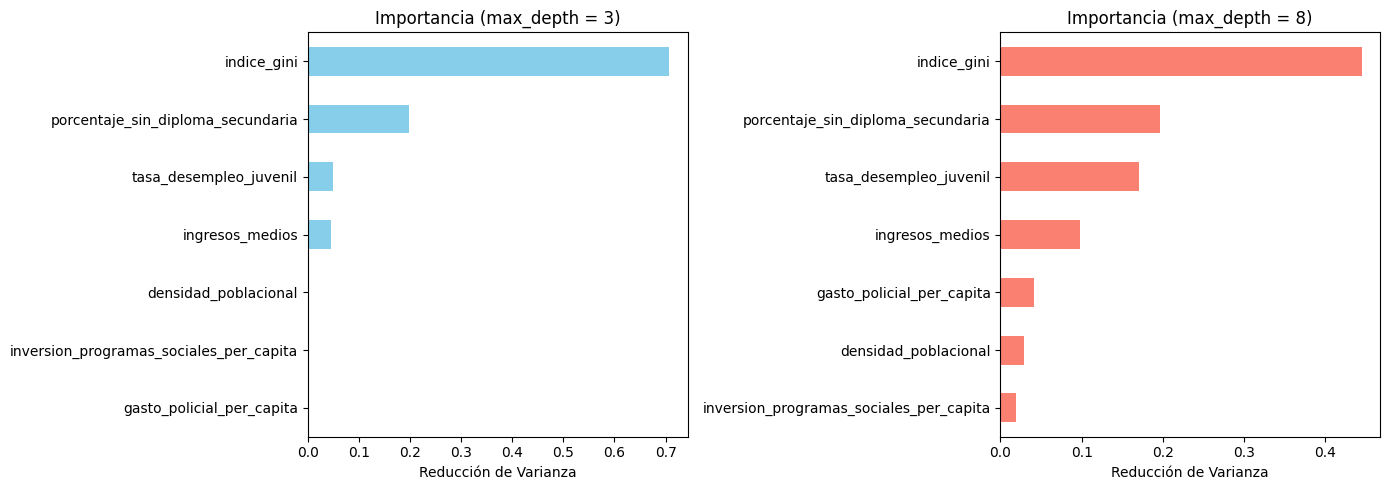

In [ ]:
# Crear DataFrame de importancias
df_imp = pd.DataFrame({
    'Variable': X_inicial_cols,
    'Importancia (max_depth=3)': dt_init_lim.feature_importances_,
    'Importancia (max_depth=8)': dt_init_deep.feature_importances_
}).sort_values(by='Importancia (max_depth=3)', ascending=False)

print("=== IMPORTANCIA DE CARACTERÍSTICAS ===")
display(df_imp)

# Gráfico de barras horizontal
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp_lim = pd.Series(dt_init_lim.feature_importances_, index=X_inicial_cols).sort_values(ascending=True)
imp_deep = pd.Series(dt_init_deep.feature_importances_, index=X_inicial_cols).sort_values(ascending=True)

imp_lim.plot(kind='barh', ax=axes[0], color='skyblue')
axes[0].set_title('Importancia (max_depth = 3)')
axes[0].set_xlabel('Reducción de Varianza')

imp_deep.plot(kind='barh', ax=axes[1], color='salmon')
axes[1].set_title('Importancia (max_depth = 8)')
axes[1].set_xlabel('Reducción de Varianza')

plt.tight_layout()
plt.show()

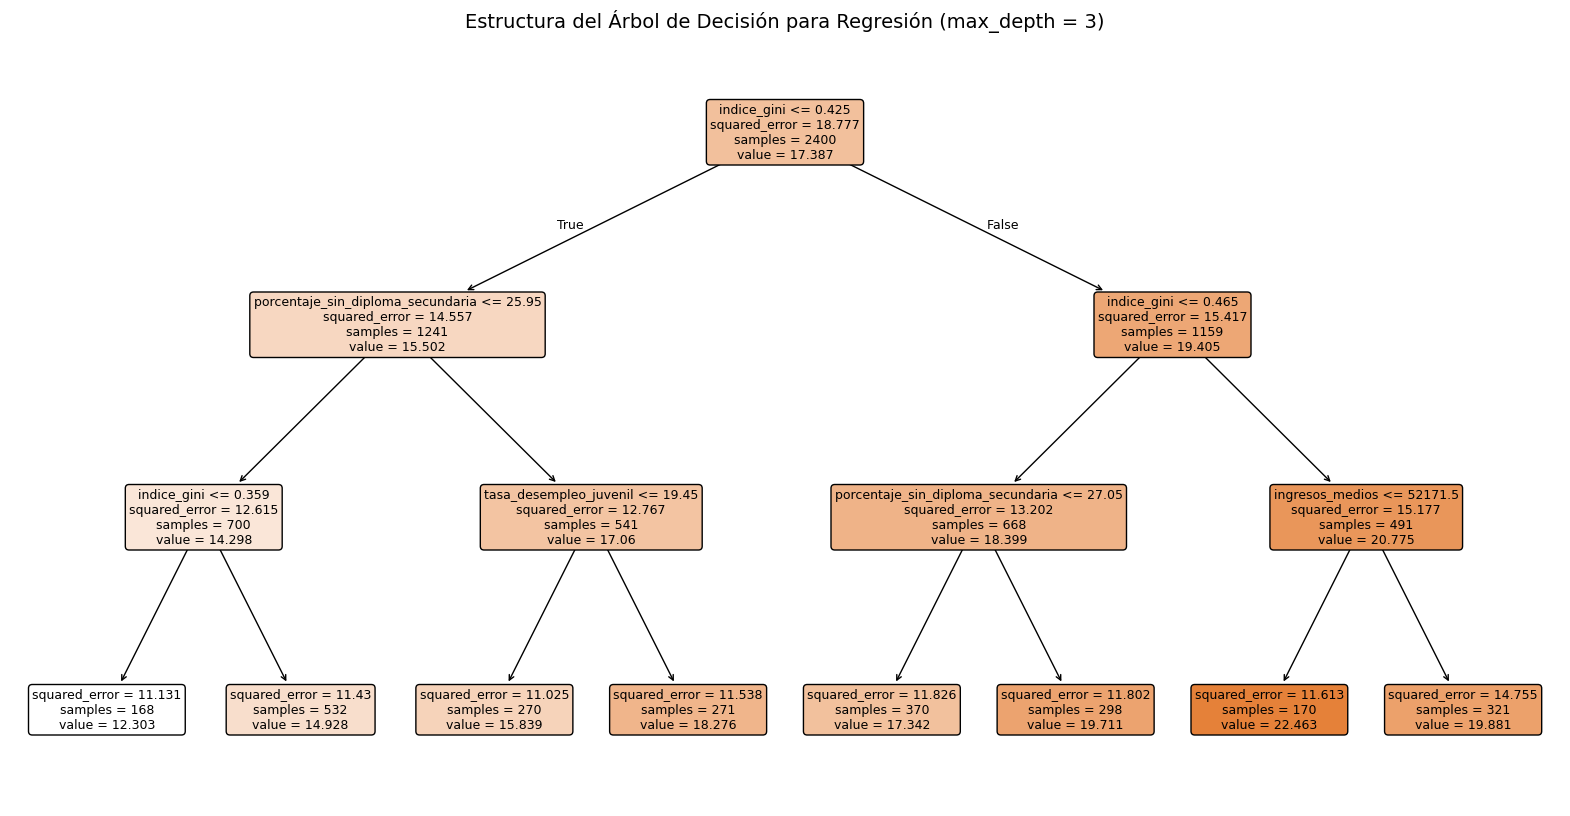

In [ ]:
from sklearn.tree import plot_tree

# Diagrama del árbol para max_depth = 3
plt.figure(figsize=(20, 10))
plot_tree(
    dt_init_lim,
    feature_names=X_inicial_cols,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Estructura del Árbol de Decisión para Regresión (max_depth = 3)", fontsize=14)
plt.show()

# Conclusiones Requeridas del Proyecto (Análisis Sencillo y Directo)

### 1. Interpretación vs. Predicción: ¿Cuáles son los 3 factores con mayor influencia?
De acuerdo a las reglas lógicas y los resultados de importancia de nuestro modelo, los tres factores socioeconómicos que ejercen la mayor influencia sobre el incremento de la tasa de asesinatos son:
*   **Desigualdad económica (Índice de Gini):** Es el factor determinante principal por un amplio margen.
*   **Nivel educativo (Porcentaje de población sin diploma de secundaria):** Actúa como el segundo indicador de vulnerabilidad más crítico.
*   **Desempleo juvenil:** Representa el tercer elemento con impacto directo en las tasas analizadas.

### 2. Mejor Rendimiento: ¿Qué algoritmo o configuración arrojó el R² más alto?
La configuración del **Árbol de Decisión Limitado (max_depth = 3)** obtuvo el mejor rendimiento real con un **R² de prueba de 34.23%** (comparado con el 32.79% del árbol profundo de max_depth=8, o el bajísimo 4.26% del árbol sin límite).
*   **¿A qué se debe?** A que al limitar artificialmente los niveles del árbol a 3 pasos, obligamos al modelo a quedarse únicamente con los patrones más generales y reales de la población, impidiendo que intente "memorizar" el ruido o los casos excepcionales del entrenamiento.

### 3. Importancia de Variables: Comparación de prioridades
En nuestro modelo de Árbol de Decisión:
*   La variable de mayor peso absoluto es el **Índice de Gini (70.75%)**, seguida por el **Porcentaje sin Secundaria (19.83%)** y la **Tasa de Desempleo Juvenil (4.89%)**.
*   **¿Por qué se enfoca de esta manera un modelo no lineal?** A diferencia de modelos lineales que calculan un impacto continuo ponderando todas las variables por igual, el modelo de árbol funciona dividiendo la población en grupos ("si la desigualdad supera X valor..."). Al segmentar los datos de forma no lineal, detecta de inmediato que resolver la desigualdad y la educación abre o cierra caminos cruciales de forma masiva, dejando el resto de variables como detalles secundarios.

### 4. Sobreajuste (Overfitting): ¿Cómo se demostró en el Árbol de Decisión?
El sobreajuste quedó perfectamente en evidencia al comparar los resultados de la configuración **Libre (sin límite de profundidad)**:
*   **R² en Entrenamiento:** **1.00 (100% de precisión)**. El árbol creció tanto que creó una regla específica para cada registro de entrenamiento, prediciendo perfectamente datos que ya conocía.
*   **R² en Prueba:** **0.04 (4.2% de precisión)**. Al enfrentarse a datos nuevos que no memorizó, sus reglas hiper-específicas fallaron por completo.
Esta abismal diferencia demuestra que un modelo demasiado complejo pierde toda su utilidad práctica para hacer predicciones en el mundo real.

### 5. Recomendación de Modelo para Políticas Públicas y Programas Sociales
Si el objetivo es convencer al gobierno de destinar recursos a un programa social específico, el modelo recomendado es el **Árbol de Decisión de Profundidad Limitada (max_depth = 3)**.
*   **¿Por qué?** Porque ofrece una **interpretabilidad visual inigualable**. Un político o tomador de decisiones no necesita entender de matemáticas avanzadas para comprender el gráfico del árbol. En él se observa con total claridad matemática que si se reduce la deserción escolar (porcentaje sin secundaria) o la desigualdad, la tasa de asesinatos estimada disminuye inmediatamente de forma escalonada. Esto justifica la inversión social de forma lógica, transparente y sumamente convincente.